<div style="line-height: 1.8;">

## **Genome Identification**

Исходную последовательность исследовали по файлу `data/raw/genome.fna`. Определили размер генома, нуклеотидный состав и долю неопределённых оснований, после чего сопоставили последовательность с референсом NCBI `NC_000913.3`.

В составе FASTA обнаружили одну последовательность длиной 4 641 652 п.н. При побуквенном сравнении установили её полную идентичность геному *Escherichia coli* K-12 MG1655. Референс использовали для оценки результатов структурной аннотации; основной каталог геномных признаков получили при отдельном запуске Bakta.

</div>

In [1]:
import sys
import Bio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO

print("Python:", sys.version.split()[0])
print("Biopython:", Bio.__version__)
print("Окружение:", sys.executable)

Matplotlib is building the font cache; this may take a moment.


Python: 3.11.17
Biopython: 1.88
Окружение: /Users/danasokol/miniconda3/envs/genome-base/bin/python


In [2]:
import os

# Ищем корень проекта при запуске из notebooks, проекта или общей рабочей папки.
configured_root = os.environ.get("GENOME_ANNOTATION_PROJECT_ROOT")
if configured_root:
    project_dir = Path(configured_root).expanduser().resolve()
else:
    candidates = [candidate for base in (Path.cwd(), *Path.cwd().parents)
                  for candidate in (base, base / "projects/genome_annotation")]
    project_dir = next((p for p in candidates if (p / "data/raw/genome.fna").is_file()), None)
if project_dir is None or not (project_dir / "data/raw/genome.fna").is_file():
    raise FileNotFoundError("Откройте ноутбук из папки проекта или задайте GENOME_ANNOTATION_PROJECT_ROOT")

genome_path = project_dir / "data/raw/genome.fna"
print("Папка проекта:", project_dir)

Папка проекта: /Users/danasokol/Desktop/bioinformatics/projects/genome_annotation


<div style="line-height: 1.8;">

### **Размер и нуклеотидный состав генома**

GC-состав рассчитали относительно суммарного числа A, C, G и T; долю N определили относительно полной длины последовательности. Содержание GC составило 50,79%, неопределённые основания отсутствовали.

Для оценки неоднородности нуклеотидного состава построили GC-профиль с окном 10 000 п.н. Наблюдаемые локальные отклонения характеризовали состав отдельных участков, однако сами по себе не служили доказательством горизонтального переноса.

</div>

In [3]:
#Количество последовательностей и общая длина генома

sequences = list(SeqIO.parse(genome_path, "fasta"))

print("Количество последовательностей:", len(sequences))
print("Общая длина генома:", sum(len(s) for s in sequences), "п.н.")

assert len(sequences) == 1, "Этот разбор рассчитан на одну хромосому"

Количество последовательностей: 1
Общая длина генома: 4641652 п.н.


In [4]:
record = sequences[0]

print("ID:", record.id)
print("Описание:", record.description)
print("Длина:", len(record.seq))

ID: 1
Описание: 1
Длина: 4641652


In [5]:
from collections import Counter

seq = str(record.seq).upper()
counts = Counter(seq)

for base in "ACGTN":
    print(f"{base}: {counts.get(base, 0):,}")

acgt = sum(counts.get(base, 0) for base in "ACGT")
gc = counts["G"] + counts["C"]

gc_percent = 100 * gc / acgt if acgt else float("nan")
n_percent = 100 * counts["N"] / len(seq)

print(f"\nGC-состав: {gc_percent:.2f}%")
print(f"Содержание N: {n_percent:.4f}%")
print("Другие символы:", {k: v for k, v in counts.items() if k not in "ACGTN"})

A: 1,142,742
C: 1,180,091
G: 1,177,437
T: 1,141,382
N: 0

GC-состав: 50.79%
Содержание N: 0.0000%
Другие символы: {}


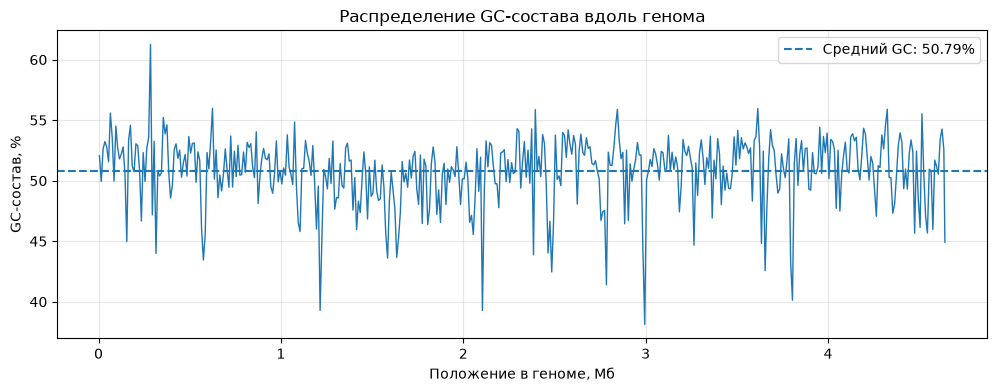

In [6]:
#Построим GC-профиль вдоль генома

window_size = 10_000
positions = []
gc_values = []

for start in range(0, len(seq), window_size):
    fragment = seq[start:start + window_size]

    gc = fragment.count("G") + fragment.count("C")
    acgt = sum(fragment.count(base) for base in "ACGT")

    positions.append((start + len(fragment) / 2) / 1e6)
    gc_values.append(100 * gc / acgt if acgt else np.nan)

plt.figure(figsize=(12, 4))

plt.plot(positions, gc_values, linewidth=1)
plt.axhline(gc_percent, linestyle="--",
            label=f"Средний GC: {gc_percent:.2f}%")

plt.xlabel("Положение в геноме, Мб")
plt.ylabel("GC-состав, %")
plt.title("Распределение GC-состава вдоль генома")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<div style="line-height: 1.8;">

### **Идентификация последовательности**

Из центральной части генома выделили фрагмент длиной 1000 п.н. и сохранили его в `data/processed/blast_fragment.fasta` для предварительной идентификации. Запрос BLAST в данном ноутбуке не выполняли; заключение об идентичности получили при сравнении полных последовательностей.

В качестве референса использовали сохранённую запись `data/processed/NC_000913.3.gbk`. Полное совпадение подтвердило возможность прямого сопоставления геномных координат без дополнительного выравнивания.

</div>

In [7]:
# Подготовим 1000 нуклеотидов для BLAST
mid = len(record.seq) // 2

fragment = SeqRecord(
    record.seq[mid:mid + 1000],
    id="genome_middle_fragment",
    description=""
)

output = project_dir / "data/processed/blast_fragment.fasta"

output.parent.mkdir(parents=True, exist_ok=True)
SeqIO.write(fragment, output, "fasta")

print("Файл сохранён:", output)

Файл сохранён: /Users/danasokol/Desktop/bioinformatics/projects/genome_annotation/data/processed/blast_fragment.fasta


In [8]:
reference_path = project_dir / "data/processed/NC_000913.3.gbk"
reference = SeqIO.read(reference_path, "genbank")

same = str(record.seq).upper() == str(reference.seq).upper()
print("Референс:", reference.id)
print("Длина референса:", len(reference.seq))
print("Полное совпадение последовательностей:", same)
assert same, "Для координатного сравнения нужен референс с той же последовательностью"

Референс: NC_000913.3
Длина референса: 4641652
Полное совпадение последовательностей: True


<div style="line-height: 1.8;">

### **Референсная структурная и функциональная аннотация E. coli K-12 MG1655**

По записи GenBank определили состав референсной аннотации. Подсчитали записи `gene`, CDS, некодирующих РНК и других признаков. Учитывали различие между числом записей и числом генов: отдельные записи `gene` и CDS могли относиться к одному локусу.

Распределение признаков использовали как количественную характеристику референса. Совпадение общего числа CDS рассматривали отдельно от совпадения их расположения.

</div>

In [9]:
annotated_genome = reference
print("Организм:", annotated_genome.annotations["organism"])
print("Количество записей признаков:", len(annotated_genome.features))

Организм: Escherichia coli str. K-12 substr. MG1655
Количество записей признаков: 9285


In [10]:
#Типы аннотированных элементов в референсе
feature_counts = Counter(feature.type for feature in annotated_genome.features)

for feature_type, count in feature_counts.most_common():
    print(f"{feature_type:20s} {count}")

gene                 4651
CDS                  4318
ncRNA                108
tRNA                 86
mobile_element       50
misc_feature         48
rRNA                 22
source               1
rep_origin           1


<div style="line-height: 1.8;">

Из референсной аннотации сформировали таблицу CDS с идентификаторами, названиями генов, координатами и описаниями белковых продуктов. Координаты Biopython преобразовали в систему с отсчётом от 1 и включением обеих границ: к начальной позиции прибавили единицу, конечную сохранили.

Для составных CDS отдельно учли длину частей записи в поле `length_nt`. Поля `start` и `end` отражали внешний интервал таких CDS, поэтому совпадение этих границ не приравнивали к совпадению их внутренней структуры.

</div>

In [11]:
#Таблица генов
genes = []

for feature in annotated_genome.features:
    if feature.type != "CDS":
        continue
    genes.append({
        "gene": feature.qualifiers.get("gene", ["unknown"])[0],
        "locus_tag": feature.qualifiers.get("locus_tag", [""])[0],
        "start": int(feature.location.start) + 1,
        "end": int(feature.location.end),
        "strand": feature.location.strand,
        "length_nt": len(feature.location),
        "is_compound": len(feature.location.parts) > 1,
        "product": feature.qualifiers.get("product", ["unknown"])[0]
    })

genes_df = pd.DataFrame(genes)

display(genes_df.head(10))

,gene,locus_tag,start,end,strand,length_nt,is_compound,product
0,thrL,b0001,190,255,1,66,False,thr operon leader peptide
1,thrA,b0002,337,2799,1,2463,False,fused aspartate kinase/homoserine dehydrogenase 1
2,thrB,b0003,2801,3733,1,933,False,homoserine kinase
3,thrC,b0004,3734,5020,1,1287,False,threonine synthase
4,yaaX,b0005,5234,5530,1,297,False,DUF2502 domain-containing protein YaaX
5,yaaA,b0006,5683,6459,-1,777,False,DNA binding and peroxide stress response prote...
6,yaaJ,b0007,6529,7959,-1,1431,False,putative transporter YaaJ
7,talB,b0008,8238,9191,1,954,False,transaldolase B
8,mog,b0009,9306,9893,1,588,False,molybdopterin adenylyltransferase
9,satP,b0010,9928,10494,-1,567,False,acetate/succinate:H(+) symporter


In [12]:
# GenBank остаётся исходным снимком NCBI; сохраняем только извлечённую таблицу.
ref_dir = project_dir / "data/processed"
ref_dir.mkdir(parents=True, exist_ok=True)
genes_df.to_csv(ref_dir / "reference_CDS.tsv", sep="\t", index=False)

<div style="line-height: 1.8;">

Псевдогены подсчитали по квалификаторам `pseudo` и `pseudogene` в записях типа `gene`. В референсе учли 145 таких записей. Самостоятельное предсказание псевдогенов на этом этапе не выполняли.

</div>

In [13]:
# Псевдогены
pseudogenes = [
    f for f in annotated_genome.features
    if f.type == "gene"
    and ("pseudo" in f.qualifiers
         or "pseudogene" in f.qualifiers)
]

print("Псевдогенов:", len(pseudogenes))

for feature in pseudogenes[:10]:
    print(
        feature.qualifiers.get("gene", ["unknown"])[0],
        feature.location
    )

Псевдогенов: 145
yafU [238745:239084](-)
yafF [239189:239378](+)
lfhA [248357:250070](-)
lafU [250071:250827](+)
ykfJ [253466:253733](+)
prfH [253701:254202](+)
crl [257828:259006](+)
ykfN [263149:263212](-)
ykfL [266552:266774](-)
ykfK [266775:266967](-)


<div style="line-height: 1.8;">

### **Prodigal**

В рамках дополнительной оценки структурной аннотации проанализировали результаты отдельного запуска Prodigal 2.6.3. В предсказании и референсе учли по 4318 CDS. Точное совпадение внешних границ и цепи установили для 3889 записей, что составило 90,06% от числа CDS NCBI.

Для 429 референсных CDS полного совпадения внешних координат не установили. Результаты Prodigal использовали для анализа расхождений и не включали в основной каталог Bakta.

</div>

In [14]:
# Проверка первичного нахождения CDS
prodigal_dir = project_dir /"results/structural/prodigal"

proteins = list(SeqIO.parse(prodigal_dir / "proteins.faa", "fasta"))

n_prodigal = len(proteins)
n_reference = len(genes_df)

print(f"Prodigal: {n_prodigal} CDS")
print(f"NCBI:     {n_reference} CDS")
print(f"Разница:  {n_prodigal - n_reference:+d} CDS")

Prodigal: 4318 CDS
NCBI:     4318 CDS
Разница:  +0 CDS


In [15]:
#Координаты
gff_path = prodigal_dir / "genes.gff"
with open(gff_path) as f:
    for i, line in enumerate(f):
        if i == 10:
            break
        print(line.strip())

##gff-version  3
# Sequence Data: seqnum=1;seqlen=4641652;seqhdr="1"
# Model Data: version=Prodigal.v2.6.3;run_type=Single;model="Ab initio";gc_cont=50.79;transl_table=11;uses_sd=1
1	Prodigal_v2.6.3	CDS	337	2799	337.5	+	0	ID=1_1;partial=00;start_type=ATG;rbs_motif=GGAG/GAGG;rbs_spacer=5-10bp;gc_cont=0.531;conf=99.99;score=337.53;cscore=320.95;sscore=16.58;rscore=11.24;uscore=1.40;tscore=3.94;
1	Prodigal_v2.6.3	CDS	2801	3733	118.1	+	0	ID=1_2;partial=00;start_type=ATG;rbs_motif=AGGAG;rbs_spacer=5-10bp;gc_cont=0.563;conf=100.00;score=118.07;cscore=97.71;sscore=20.37;rscore=14.85;uscore=0.32;tscore=3.94;
1	Prodigal_v2.6.3	CDS	3734	5020	194.3	+	0	ID=1_3;partial=00;start_type=ATG;rbs_motif=GGA/GAG/AGG;rbs_spacer=5-10bp;gc_cont=0.528;conf=99.99;score=194.28;cscore=189.96;sscore=4.33;rscore=2.99;uscore=-3.88;tscore=3.94;
1	Prodigal_v2.6.3	CDS	5234	5530	8.2	+	0	ID=1_4;partial=00;start_type=GTG;rbs_motif=AGGAG;rbs_spacer=5-10bp;gc_cont=0.539;conf=86.80;score=8.19;cscore=0.54;sscore=7.65;rscore=1

In [16]:
columns = ["seqid", "source", "type", "start", "end", "score", "strand", "phase", "attributes"]

prodigal_df = pd.read_csv(
    gff_path,
    sep="\t",
    comment="#",
    header=None,
    names=columns
)
prodigal_df = prodigal_df[prodigal_df["type"] == "CDS"].copy()

prodigal_df["strand"] = prodigal_df["strand"].map({
    "+": 1,
    "-": -1
})

display(prodigal_df.head())

,seqid,source,type,start,end,score,strand,phase,attributes
0,1,Prodigal_v2.6.3,CDS,337,2799,337.5,1,0,ID=1_1;partial=00;start_type=ATG;rbs_motif=GGA...
1,1,Prodigal_v2.6.3,CDS,2801,3733,118.1,1,0,ID=1_2;partial=00;start_type=ATG;rbs_motif=AGG...
2,1,Prodigal_v2.6.3,CDS,3734,5020,194.3,1,0,ID=1_3;partial=00;start_type=ATG;rbs_motif=GGA...
3,1,Prodigal_v2.6.3,CDS,5234,5530,8.2,1,0,ID=1_4;partial=00;start_type=GTG;rbs_motif=AGG...
4,1,Prodigal_v2.6.3,CDS,5683,6459,117.7,-1,0,ID=1_5;partial=00;start_type=ATG;rbs_motif=AGG...


In [17]:
# Сравниваем внешние границы CDS и цепь.
reference_coords = set(
    zip(
        genes_df["start"],
        genes_df["end"],
        genes_df["strand"]
    )
)

prodigal_coords = set(
    zip(
        prodigal_df["start"],
        prodigal_df["end"],
        prodigal_df["strand"]
    )
)

exact_matches = reference_coords & prodigal_coords

print("CDS NCBI:", len(reference_coords))
print("CDS Prodigal:", len(prodigal_coords))
print("Совпадений внешних границ и цепи:", len(exact_matches))

print(
    "Доля совпадений относительно NCBI:",
    f"{len(exact_matches) / len(reference_coords) * 100:.2f}%"
)

print("CDS NCBI без точного совпадения:",
      len(reference_coords - prodigal_coords))

print("CDS Prodigal без точного совпадения:",
      len(prodigal_coords - reference_coords))

genes_df["exact_match"] = [
    (start, end, strand) in prodigal_coords
    for start, end, strand in zip(
        genes_df["start"],
        genes_df["end"],
        genes_df["strand"]
    )
]

mismatches = genes_df[~genes_df["exact_match"]].copy()

print("Генов с несовпадающими координатами:", len(mismatches))

display(mismatches.head(20))

CDS NCBI: 4318
CDS Prodigal: 4318
Совпадений внешних границ и цепи: 3889
Доля совпадений относительно NCBI: 90.06%
CDS NCBI без точного совпадения: 429
CDS Prodigal без точного совпадения: 429
Генов с несовпадающими координатами: 429


,gene,locus_tag,start,end,strand,length_nt,is_compound,product,exact_match
0,thrL,b0001,190,255,1,66,False,thr operon leader peptide,False
11,mbiA,b0012,10830,11315,1,486,False,uncharacterized protein MbiA,False
16,mokC,b0018,16751,16960,-1,210,False,regulatory protein MokC,False
19,nhaR,b0020,18715,19620,1,906,False,DNA-binding transcriptional activator NhaR,False
20,insB1,b0021,19811,20314,-1,504,False,IS1 family protein InsB,False
23,yaaY,b0024,21181,21399,1,219,False,DUF2575 domain-containing protein YaaY,False
47,folA,b0048,49823,50302,1,480,False,dihydrofolate reductase,False
75,leuL,b0075,83622,83708,-1,87,False,leu operon leader peptide,False
77,yabR,b4726,85467,85511,-1,45,False,protein YabR,False
97,secM,b0097,107705,108217,1,513,False,SecA translation regulator,False


<div style="line-height: 1.8;">

Расхождения координат рассмотрели с учётом возможного выбора альтернативного старта трансляции, различий в составе предсказанных CDS и особенностей референсной разметки. Для разграничения этих случаев сопоставили стоп-границы на одной цепи.

Совпадение стоп-границ установили для 4139 пар записей; в 250 из них стартовые границы различались. Сдвиг стартов рассчитали в геномных координатах. Его знак рассматривали с учётом направления цепи, поскольку положительное смещение не имело единого значения для удлинения или укорочения CDS на обеих цепях.

</div>

In [18]:
# Координаты границ

ref = genes_df.copy()
pred = prodigal_df.copy()

for df in [ref, pred]:
    df["stop_boundary"] = np.where(
        df["strand"] == 1,
        df["end"],
        df["start"]
    )

    df["start_boundary"] = np.where(
        df["strand"] == 1,
        df["start"],
        df["end"]
    )

In [19]:
stop_matches = ref.merge(
    pred,
    on=["strand", "stop_boundary"],
    suffixes=("_ncbi", "_prodigal")
)

stop_matches["same_start"] = (
    stop_matches["start_boundary_ncbi"]
    == stop_matches["start_boundary_prodigal"]
)

stop_matches["start_shift_nt"] = (
    stop_matches["start_boundary_prodigal"]
    - stop_matches["start_boundary_ncbi"]
)

print("Совпадений по стоп-границе:", len(stop_matches))

print(
    "Одинаковые старты:",
    stop_matches["same_start"].sum()
)

print(
    "Разные старты при одинаковом стопе:",
    (~stop_matches["same_start"]).sum()
)

Совпадений по стоп-границе: 4139
Одинаковые старты: 3889
Разные старты при одинаковом стопе: 250


In [20]:
different_starts = stop_matches[
    ~stop_matches["same_start"]
].copy()

display(
    different_starts[
        [
            "gene",
            "start_ncbi",
            "end_ncbi",
            "start_prodigal",
            "end_prodigal",
            "strand",
            "start_shift_nt"
        ]
    ].head(20)
)

,gene,start_ncbi,end_ncbi,start_prodigal,end_prodigal,strand,start_shift_nt
14,mokC,16751,16960,16751,16903,-1,-57
17,nhaR,18715,19620,18721,19620,1,6
18,insB1,19811,20314,19811,20188,-1,-126
44,folA,49823,50302,49712,50302,1,-111
92,secM,107705,108217,107630,108217,1,-75
105,aroP,120178,121551,120178,121548,-1,-3
115,yacC,136570,136917,136570,136878,-1,-39
136,pcnB,157729,159126,157729,159093,-1,-33
143,mrcB,164865,167264,164730,167264,1,-135
158,yaeI,184257,185069,184257,185000,-1,-69


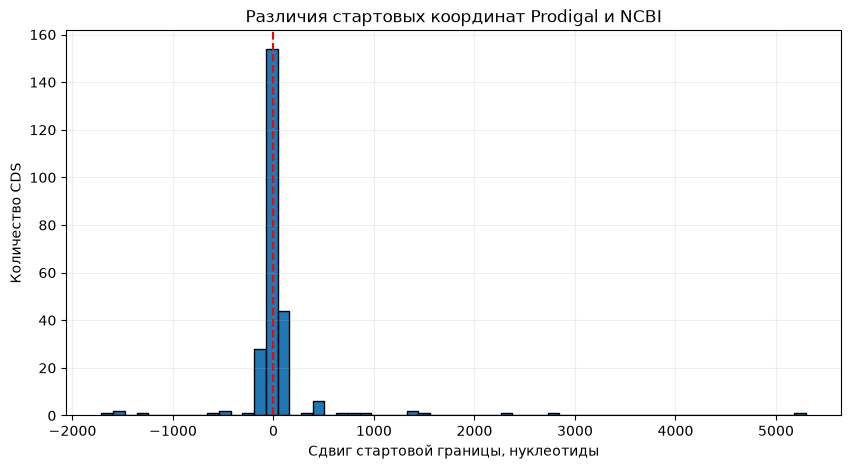

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(
    different_starts["start_shift_nt"],
    bins=60,
    edgecolor="black"
)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Сдвиг стартовой границы, нуклеотиды")
plt.ylabel("Количество CDS")
plt.title("Различия стартовых координат Prodigal и NCBI")
plt.grid(alpha=0.2)
plt.show()

In [22]:
#Несовпадение по стоп границе
matched_stops = set(
    zip(
        stop_matches["strand"],
        stop_matches["stop_boundary"]
    )
)

unmatched_ref = ref[
    ~ref.apply(
        lambda row: (
            row["strand"],
            row["stop_boundary"]
        ) in matched_stops,
        axis=1
    )
].copy()

print("CDS без совпадения стоп-границы:", len(unmatched_ref))

display(unmatched_ref[["gene", "start", "end", "strand", "product"]].head(20))

CDS без совпадения стоп-границы:

 179


,gene,start,end,strand,product
0,thrL,190,255,1,thr operon leader peptide
11,mbiA,10830,11315,1,uncharacterized protein MbiA
23,yaaY,21181,21399,1,DUF2575 domain-containing protein YaaY
75,leuL,83622,83708,-1,leu operon leader peptide
77,yabR,85467,85511,-1,protein YabR
103,yacM,113244,113288,1,protein YacM
155,yadX,175048,175095,1,protein YadX
157,yadW,176552,176617,1,protein YadW
209,ykfO,234288,234320,1,protein YkfO
249,insN,270278,272190,1,CP4-6 prophage; IS911A regulator fragment


<div style="line-height: 1.8;">

### **Связь расхождений с длиной CDS**

Для CDS без совпадения стоп-границы оценили распределение длин, медиану и долю участков короче 300 п.н. Полученные показатели сопоставили с распределением всех CDS NCBI. Плотности рассчитали по полным выборкам; на графике отобразили диапазон до 1500 п.н.

Дополнительно определили долю совпадений внешних границ в группах длины. Показатель `exact_match_pct` использовали как меру соответствия референсной разметке, а не как оценку биологической достоверности предсказания.

</div>

Медиана всех CDS: 825.0
Медиана несовпавших CDS: 102.0
Доля CDS короче 300 п.н. среди всех: 12.1%
Доля CDS короче 300 п.н. среди несовпавших: 88.3%


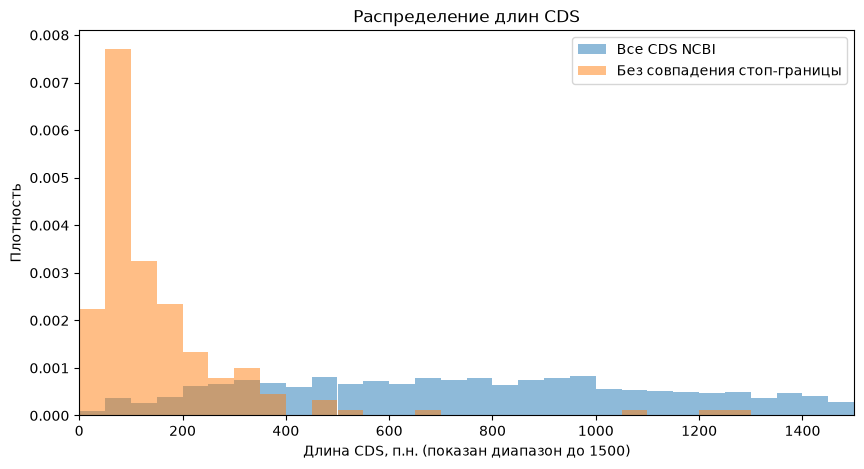

In [23]:
#Посмотрим на распределение длин

import numpy as np
import matplotlib.pyplot as plt

# Длина CDS из NCBI
ref["length"] = ref["length_nt"]

# Все CDS референса
all_lengths = ref["length"]

# CDS без совпадения стоп-границы
unmatched_ref["length"] = unmatched_ref["length_nt"]

unmatched_lengths = unmatched_ref["length"]

print("Медиана всех CDS:", all_lengths.median())
print("Медиана несовпавших CDS:", unmatched_lengths.median())

print(
    "Доля CDS короче 300 п.н. среди всех:",
    f"{(all_lengths < 300).mean() * 100:.1f}%"
)

print(
    "Доля CDS короче 300 п.н. среди несовпавших:",
    f"{(unmatched_lengths < 300).mean() * 100:.1f}%"
)

plt.figure(figsize=(10, 5))

bins = np.arange(0, int(all_lengths.max()) + 51, 50)

plt.hist(
    all_lengths,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Все CDS NCBI"
)

plt.hist(
    unmatched_lengths,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Без совпадения стоп-границы"
)

plt.xlim(0, 1500)
plt.xlabel("Длина CDS, п.н. (показан диапазон до 1500)")
plt.ylabel("Плотность")
plt.title("Распределение длин CDS")
plt.legend()
plt.show()

In [24]:
ref["exact_match"] = [
    (start, end, strand) in prodigal_coords
    for start, end, strand in zip(
        ref["start"], ref["end"], ref["strand"]
    )
]

bins = [0, 150, 300, 600, 1000, 2000, np.inf]
labels = [
    "<150", "150–299", "300–599",
    "600–999", "1000–1999", "≥2000"
]

ref["length_group"] = pd.cut(
    ref["length"],
    bins=bins,
    labels=labels,
    right=False
)

quality_by_length = (
    ref.groupby("length_group", observed=True)
    .agg(
        total=("exact_match", "size"),
        matched=("exact_match", "sum"),
        exact_match_pct=("exact_match", "mean")
    )
    .reset_index()
)

quality_by_length["exact_match_pct"] *= 100

display(quality_by_length)

,length_group,total,matched,exact_match_pct
0,<150,157,33,21.019108
1,150–299,364,309,84.890110
2,300–599,911,836,91.767289
3,600–999,1303,1231,94.474290
4,1000–1999,1319,1244,94.313874
5,≥2000,264,236,89.393939


<div style="line-height: 1.8;">

Медиана длины CDS без совпадения стоп-границы составила 102 п.н., тогда как для всех CDS NCBI — 825 п.н. Доля участков короче 300 п.н. достигла 88,3% в группе расхождений и 12,1% в полной выборке. Таким образом, среди несовпавших записей преобладали короткие CDS.

Полученная связь не позволила признать все короткие предсказания ошибочными. Возможные причины расхождений включали различия стартовых позиций и особенности составных референсных записей; их вклад для отдельных локусов в этом анализе не устанавливали.

</div>